Fron N-Grams to logistic regresssion 
### Dataset Setup

The IMDB dataset contains movie reviews labeled as positive or negative. we used a balanced subset of 5,000 training reviews and 1,000 test reviews. The training and test sets are sampled separately, and a fixed random seed is used to make the selection reproducible.

In [27]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import re
import html
import numpy as np
from collections import Counter, defaultdict

from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")

print(imdb)
print(imdb["train"][0]["text"][:300])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h


In [29]:
#from datasets import load_dataset

#imdb = load_dataset("imdb")

#print(imdb)
#print(imdb["train"][0])

inspecting the raw data

In [30]:
print("Training reviews:", len(imdb["train"]))
print("Test reviews:", len(imdb["test"]))

for i in range(5):
    review = imdb["train"][i]
    print("\nLabel:", review["label"])
    print("Review:", review["text"][:500])
    from collections import Counter



Training reviews: 25000
Test reviews: 25000

Label: 0
Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Label: 0
Review: "I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? 

In [31]:
#Extract the exact balanced subset
def extract_balanced_subset(dataset, samples_per_class, seed=42):
    texts = []
    labels = []

    for label in [0, 1]:
        class_indices = [
            i for i, item in enumerate(dataset)
            if item["label"] == label
        ]

        rng = np.random.default_rng(seed + label)
        chosen_indices = rng.choice(
            class_indices,
            size=samples_per_class,
            replace=False
        )

        for index in chosen_indices:
            texts.append(dataset[int(index)]["text"])
            labels.append(label)

    # Shuffle the combined subset
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(texts))

    texts = [texts[i] for i in order]
    labels = np.array([labels[i] for i in order])

    return texts, labels


train_texts, y_train = extract_balanced_subset(
    imdb["train"], 2500, seed=42
)

test_texts, y_test = extract_balanced_subset(
    imdb["test"], 500, seed=123
)

print("Training:", len(train_texts))
print("Training negative:", np.sum(y_train == 0))
print("Training positive:", np.sum(y_train == 1))

print("Testing:", len(test_texts))
print("Testing negative:", np.sum(y_test == 0))
print("Testing positive:", np.sum(y_test == 1))

Training: 5000
Training negative: 2500
Training positive: 2500
Testing: 1000
Testing negative: 500
Testing positive: 500


### Text Preprocessing and Tokenization

Text preprocessing prepares the reviews for language modeling. I decode HTML entities, remove HTML tags, convert text to lowercase, and tokenize the reviews into words using regular expressions. 
 added `<s>` and `</s>` tokens to mark the beginning and end of each review.

In [32]:
#preprocessing and tokenization
def clean_text(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalize case
    text = text.lower()

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [33]:
def tokenize(text):
    text = clean_text(text)

    # Keep alphabetic words and internal apostrophes
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    # Add sentence boundary markers
    return ["<s>"] + tokens + ["</s>"]

In [34]:
#testing
example = "<p>This MOVIE isn't bad! I loved it.</p>"

print(clean_text(example))
print(tokenize(example))

this movie isn't bad! i loved it.
['<s>', 'this', 'movie', "isn't", 'bad', 'i', 'loved', 'it', '</s>']


In [35]:
#: Keeping the original text and labels for evaluation
# but  the tokenized versions for all subsequent language-model calculations.

X_train_tokens = [tokenize(text) for text in train_texts]
X_test_tokens = [tokenize(text) for text in test_texts]

print("Original review:")
print(train_texts[0][:300])

print("\nTokenized review:")
print(X_train_tokens[0][:40])

print("\nNumber of training reviews:", len(X_train_tokens))
print("Number of test reviews:", len(X_test_tokens))

Original review:
I did not enjoy the film, Joshua, at all. Perhaps it is because I saw another, much better similar film titled Orphan 2 days prior but perhaps it's really just because this film was not very good. I am going with the ladder. Sure, the plot of an evil child is not exactly original but that doesn't me

Tokenized review:
['<s>', 'i', 'did', 'not', 'enjoy', 'the', 'film', 'joshua', 'at', 'all', 'perhaps', 'it', 'is', 'because', 'i', 'saw', 'another', 'much', 'better', 'similar', 'film', 'titled', 'orphan', 'days', 'prior', 'but', 'perhaps', "it's", 'really', 'just', 'because', 'this', 'film', 'was', 'not', 'very', 'good', 'i', 'am', 'going']

Number of training reviews: 5000
Number of test reviews: 1000


### Class-Conditional Bigram Language Models

I train two separate bigram language models: one using positive reviews and the other using negative reviews. The model counts how often two words appear together, estimates the probability of one word following another, and uses smoothing to handle word combinations it hasn't seen before. 
Add-1 (Laplace) smoothing prevents unseen bigrams from receiving zero probability.

In bigram model it calculates the prob of second word appearing after the first word by counting how ogten this happens in the training reviews

it estimates the probability of the next word given the previous word:
P(wi | wi-1)

p(w2,w1)= Count(w1,w2) +1 / Count(w1) +V  
Where:
- Count(w1,w2) is the bigram count.
- Count(w1) is the count of the previous token as a bigram context.
- V is the vocabulary size.
We add 1 to the bigram count and add \(V\) to the denominator so that even unseen bigrams have a small, nonzero probability.






In [36]:

# Count words using training reviews only
word_counts = Counter(token for tokens in X_train_tokens
    for token in tokens
)

#  words that appear at least twice
min_frequency = 2

lm_vocab = {
    word
    for word, count in word_counts.items()
    if count >= min_frequency
}

#keep the special tokens
lm_vocab.update(["<s>", "</s>", "<UNK>"])

#Replace rare words in training reviews with <UNK>
X_train_tokens = [
    [
        token if token in lm_vocab else "<UNK>"
        for token in tokens
    ]
    for tokens in X_train_tokens
]

#Replace unseen words in test reviews with <UNK>
X_test_tokens = [
    [
        token if token in lm_vocab else "<UNK>"
        for token in tokens
    ]
    for tokens in X_test_tokens
]

#Convert vocabulary to a sorted list
lm_vocab = sorted(lm_vocab)

print("Vocabulary size:", len(lm_vocab))
print("Sample vocabulary:", lm_vocab[:30])
print("Training reviews:", len(X_train_tokens))
print("Test reviews:", len(X_test_tokens))


Vocabulary size: 24125
Sample vocabulary: ['</s>', '<UNK>', '<s>', 'a', 'aaa', 'aag', 'aames', 'aamir', 'aaron', 'abandon', 'abandoned', 'abandoning', 'abandonment', 'abandons', 'abbas', 'abbey', "abbey's", 'abbot', 'abbott', 'abbreviated', 'abbu', 'abby', 'abc', "abc's", 'abducted', 'abduction', 'abe', 'abel', 'abernathy', 'abetted']
Training reviews: 5000
Test reviews: 1000


In [37]:
#Training the bigram model
def train_bigram_lm(token_sequences):
    bigram_counts = Counter()
    context_counts = Counter()

    for tokens in token_sequences:
        for i in range(1, len(tokens)):
            previous_word = tokens[i - 1]
            current_word = tokens[i]

            bigram_counts[(previous_word, current_word)] += 1
            context_counts[previous_word] += 1

    return {
        "bigram_counts": bigram_counts,
        "context_counts": context_counts,
        "vocab": lm_vocab,
        "vocab_size": len(lm_vocab)
    }

In [38]:
#two models each learns bigram statistics from only its own class.
positive_train_tokens = [
    tokens for tokens, label in zip(X_train_tokens, y_train)
    if label == 1
]

negative_train_tokens = [
    tokens for tokens, label in zip(X_train_tokens, y_train)
    if label == 0
]

positive_lm = train_bigram_lm(positive_train_tokens)
negative_lm = train_bigram_lm(negative_train_tokens)

print("Positive training reviews:", len(positive_train_tokens))
print("Negative training reviews:", len(negative_train_tokens))

print("\nPositive bigram examples:")
print(positive_lm["bigram_counts"].most_common(10))

print("\nNegative bigram examples:")
print(negative_lm["bigram_counts"].most_common(10))


Positive training reviews: 2500
Negative training reviews: 2500

Positive bigram examples:
[(('of', 'the'), 4260), (('in', 'the'), 2558), (('is', 'a'), 1581), (('and', 'the'), 1510), (('this', 'movie'), 1450), (('to', 'the'), 1364), (('the', 'film'), 1315), (('it', 'is'), 1262), (('this', 'film'), 1118), (('the', 'movie'), 1082)]

Negative bigram examples:
[(('of', 'the'), 3619), (('in', 'the'), 2583), (('this', 'movie'), 1794), (('to', 'be'), 1410), (('the', 'movie'), 1330), (('the', 'film'), 1285), (('and', 'the'), 1236), (('to', 'the'), 1105), (('is', 'a'), 1068), (('this', 'film'), 1036)]


Calculate log-likelihood and perplexity
Log-likelihood: Sum [log P(Wi | Wi-1)]
Perplexity: PP(d) = Exp(- LL(d) / N)
\(N\) is the number of bigram transitions in the review
Interpretation: lower perplexity means the language model finds the review's word sequence more predictable.

The better-fitting model typically has a higher log-likelihood and lower perplexity.

In [39]:
def calculate_log_likelihood(tokens, model):
    bigram_counts = model["bigram_counts"]
    context_counts = model["context_counts"]
    vocab_size = model["vocab_size"]
    log_likelihood = 0.0

    for i in range(1, len(tokens)):
        previous_word = tokens[i - 1]
        current_word = tokens[i]

        bigram_count = bigram_counts[
            (previous_word, current_word)
        ]
        context_count = context_counts[previous_word]

        probability = (
            (bigram_count + 1) /
            (context_count + vocab_size)
        )

        log_likelihood += np.log(probability)

    return log_likelihood


def calculate_perplexity(tokens, model):
    log_likelihood = calculate_log_likelihood(tokens, model)

    number_of_bigrams = len(tokens) - 1

    if number_of_bigrams == 0:
        return np.nan

    return np.exp(-log_likelihood / number_of_bigrams)

In [40]:
sample_tokens = X_test_tokens[0]

positive_ll = calculate_log_likelihood(
    sample_tokens, positive_lm
)
negative_ll = calculate_log_likelihood(
    sample_tokens, negative_lm
)

positive_pp = calculate_perplexity(
    sample_tokens, positive_lm
)
negative_pp = calculate_perplexity(
    sample_tokens, negative_lm
)

print("Actual label:", y_test[0])

print("\nPositive LM log-likelihood:", positive_ll)
print("Negative LM log-likelihood:", negative_ll)

print("\nPositive LM perplexity:", positive_pp)
print("Negative LM perplexity:", negative_pp)

Actual label: 1

Positive LM log-likelihood: -885.580003485533
Negative LM log-likelihood: -898.1379641279788

Positive LM perplexity: 2916.6711551746707
Negative LM perplexity: 3266.0383320636224


LM prediction Use the language models as a classifier
For each test review:
- If positive perplexity is lower, predict label 1.
- Otherwise, predict label 0.

In [41]:
def predict_lm(tokens, positive_lm, negative_lm):
    positive_pp = calculate_perplexity(tokens, positive_lm)
    negative_pp = calculate_perplexity(tokens, negative_lm)

    if positive_pp < negative_pp:
        return 1
    else:
        return 0

\[
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
\]

\[
F1=\frac{2PR}{P+R}
\]

In [42]:
def calculate_metrics(y_true, y_pred):
    tp = sum(
        (true == 1 and pred == 1)
        for true, pred in zip(y_true, y_pred)
    )

    tn = sum(
        (true == 0 and pred == 0)
        for true, pred in zip(y_true, y_pred)
    )

    fp = sum(
        (true == 0 and pred == 1)
        for true, pred in zip(y_true, y_pred)
    )

    fn = sum(
        (true == 1 and pred == 0)
        for true, pred in zip(y_true, y_pred)
    )

    accuracy = (tp + tn) / len(y_true)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [43]:
lm_predictions = []

for tokens in X_test_tokens:
    prediction = predict_lm(
        tokens, positive_lm, negative_lm
    )
    lm_predictions.append(prediction)

lm_metrics = calculate_metrics(y_test, lm_predictions)

print("Bigram Language Model Results")
for metric, value in lm_metrics.items():
    print(f"{metric}: {value:.4f}")

Bigram Language Model Results
Accuracy: 0.8450
Precision: 0.8678
Recall: 0.8140
F1-Score: 0.8400


For a bigram model, the next word depends only on the current last word:

W i+1=argmax_w P(w | w_i)


In [44]:
def generate_next_words(
    sentence,
    model,
    max_length=15
):
    tokens = tokenize(sentence)[:-1]  # Remove </s>
    generated = []

    bigram_counts = model["bigram_counts"]
    vocab = model["vocab"]

    for _ in range(max_length):
        previous_word = tokens[-1]

        # Only consider words observed after this context
        candidates = [
            word for word in vocab
            if bigram_counts[(previous_word, word)] > 0
        ]

        # Stop if this context has no observed continuation
        if not candidates:
            break

        next_word = max(
            candidates,
            key=lambda word: bigram_counts[
                (previous_word, word)
            ]
        )

        if next_word == "</s>":
            break

        generated.append(next_word)
        tokens.append(next_word)

    return generated

In [45]:
prompt = "this movie"

print("Prompt:", prompt)

print(
    "Positive continuation:",
    generate_next_words(
        prompt, positive_lm, max_length=10
    )
)

print(
    "Negative continuation:",
    generate_next_words(
        prompt, negative_lm, max_length=10
    )
)

Prompt: this movie
Positive continuation: ['is', 'a', 'great', 'movie', 'is', 'a', 'great', 'movie', 'is', 'a']
Negative continuation: ['is', 'a', 'movie', 'is', 'a', 'movie', 'is', 'a', 'movie', 'is']


Part 3

In [46]:
X_train_features_tokens = [
    tokenize(text) for text in train_texts
]

X_test_features_tokens = [
    tokenize(text) for text in test_texts
]

print(len(X_train_features_tokens))
print(len(X_test_features_tokens))

5000
1000


We will extract both unigrams and bigrams from these tokens.
- Unigram: one word
- Bigram: two consecutive words
Each review will be represented by a dictionary containing the number of times each feature appears.

In [47]:
def extract_feature_counts(tokens):
    # Exclude special language-model boundary tokens
    words = [
        word for word in tokens
        if word not in {"<s>", "</s>", "<UNK>"}
    ]

    features = Counter()

    # Unigrams
    for word in words:
        features[word] += 1

    # Bigrams
    for i in range(len(words) - 1):
        bigram = words[i] + " " + words[i + 1]
        features[bigram] += 1

    return features


train_feature_counts = [
    extract_feature_counts(tokens)
    for tokens in X_train_features_tokens
]

test_feature_counts = [
    extract_feature_counts(tokens)
    for tokens in X_test_features_tokens
]

print("Training documents:", len(train_feature_counts))
print("Example features:", train_feature_counts[0].most_common(10))

Training documents: 5000
Example features: [('the', 19), ('was', 11), ('i', 8), ('it', 7), ('but', 7), ('that', 7), ('and', 7), ('his', 6), ('not', 5), ('film', 4)]


We'll select the 2,000 most frequent features across the training set only
The test set must remain unseen while we make modeling decisions.

In [48]:
total_feature_counts = Counter()

for document_features in train_feature_counts:
    total_feature_counts.update(document_features)

top_features = [
    feature
    for feature, count in total_feature_counts.most_common(2000)
]

feature_to_index = {
    feature: index
    for index, feature in enumerate(top_features)
}

print("Number of selected features:", len(top_features))
print("First 100 features:", top_features[:100])

Number of selected features: 2000
First 100 features: ['the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'was', 'as', 'for', 'with', 'movie', 'but', 'film', 'of the', 'on', 'not', 'are', 'his', 'you', 'have', 'he', 'be', 'one', 'in the', 'all', 'at', 'by', 'an', 'they', 'so', 'from', 'like', 'who', 'her', 'or', 'just', 'about', "it's", 'has', 'out', 'if', 'there', 'this movie', 'some', 'what', 'more', 'good', 'very', 'when', 'and the', 'she', 'up', 'is a', 'even', 'no', 'the film', 'my', 'time', 'would', 'which', 'only', 'to the', 'story', 'really', 'to be', 'the movie', 'see', 'their', 'can', 'had', 'me', 'were', 'this film', 'it is', 'well', 'we', 'than', 'much', 'get', 'do', 'this is', 'other', 'also', 'him', 'because', 'will', 'bad', 'first', 'how', 'been', 'on the', 'into', 'people', 'great', 'its']


Calculate the Naive Bayes log-ratio \(r_j\)
Each feature gets a weight that tells us whether it is more associated with positive or negative reviews.
For feature \(j\), we calculate:
r_j =log P(f_j | y=1)-log P(f_j | y=0)]

- A positive ratio means the feature is more associated with positive reviews.
- A negative ratio means it is more associated with negative reviews.
- A ratio near zero means it provides less distinction between the classes.

(P(f_j | y=1): estimated probability of feature \(j\) in positive reviews.



(P(f_j | y=0)): estimated probability of feature \(j\) in negative reviews.

In [49]:
alpha = 1.0
num_features = len(top_features)

positive_feature_counts = np.zeros(num_features)
negative_feature_counts = np.zeros(num_features)

for document_features, label in zip(
    train_feature_counts, y_train
):
    for feature, count in document_features.items():
        index = feature_to_index.get(feature)

        if index is not None:
            if label == 1:
                positive_feature_counts[index] += count
            else:
                negative_feature_counts[index] += count

positive_total = positive_feature_counts.sum()
negative_total = negative_feature_counts.sum()

positive_probs = (
    (positive_feature_counts + alpha)
    / (positive_total + alpha * num_features)
)

negative_probs = (
    (negative_feature_counts + alpha)
    / (negative_total + alpha * num_features)
)

r = np.log(positive_probs) - np.log(negative_probs)

print("Log-ratio shape:", r.shape)
print("Example feature log-ratios:")

for i in range(10):
    print(f"{top_features[i]:25s} {r[i]:.4f}")

Log-ratio shape: (2000,)
Example feature log-ratios:
the                       0.0388
and                       0.1761
a                         0.0564
of                        0.1139
to                        -0.0175
is                        0.1232
in                        0.1270
it                        -0.0016
i                         -0.0930
this                      -0.1150


In [50]:
print("Training documents:", len(train_feature_counts))
print("Test documents:", len(test_feature_counts))
print("Number of features:", len(feature_to_index))
print("Log-ratio shape:", r.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Training documents: 5000
Test documents: 1000
Number of features: 2000
Log-ratio shape: (2000,)
Training labels: (5000,)
Test labels: (1000,)


In [51]:

# Part 3 NB-weighted feature matrices

num_features = len(feature_to_index)

def build_weighted_matrix(document_features, feature_to_index, r):
    X = np.zeros((len(document_features), len(feature_to_index)))

    for doc_index, features in enumerate(document_features):
        for feature, count in features.items():
            feature_index = feature_to_index.get(feature)

            if feature_index is not None:
                X[doc_index, feature_index] = count * r[feature_index]

    return X


X_train = build_weighted_matrix(
    train_feature_counts, feature_to_index, r
)

X_test = build_weighted_matrix(
    test_feature_counts, feature_to_index, r
)

print("Training matrix shape:", X_train.shape)
print("Test matrix shape:", X_test.shape)
print("First 10 weighted features:", X_train[0, :10])


Training matrix shape: (5000, 2000)
Test matrix shape: (1000, 2000)
First 10 weighted features: [ 0.7378121   1.23240451  0.22575049  0.34164872 -0.05256181  0.49289515
  0.         -0.01100249 -0.74397421 -0.11501678]


In [52]:

#  Standardization

# Calculate statistics using training data only
feature_means = np.mean(X_train, axis=0)
feature_stds = np.std(X_train, axis=0)

# Avoid division by zero for constant features
feature_stds[feature_stds == 0] = 1.0

# Standardize training and test data using the same statistics
X_train_scaled = (X_train - feature_means) / feature_stds
X_test_scaled = (X_test - feature_means) / feature_stds

# Add a bias column of ones
X_train_final = np.column_stack((
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
))

X_test_final = np.column_stack((
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
))

print("Final training shape:", X_train_final.shape)
print("Final test shape:", X_test_final.shape)


Final training shape: (5000, 2001)
Final test shape: (1000, 2001)


In [53]:

#  Sigmoid function

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Test the function
print("Sigmoid of 0:", sigmoid(0))
print("Sigmoid of 2:", sigmoid(2))
print("Sigmoid of -2:", sigmoid(-2))


Sigmoid of 0: 0.5
Sigmoid of 2: 0.8807970779778823
Sigmoid of -2: 0.11920292202211755


In [54]:

# Binary cross-entropy loss

def binary_cross_entropy(y_true, probabilities):
    epsilon = 1e-12

    probabilities = np.clip(
        probabilities, epsilon, 1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )

    return loss


In [55]:

# Logistic Regression 

class LogisticRegression:
    def __init__(self, learning_rate=0.1, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.loss_history = []

    def fit(self, X, y):
        num_samples, num_features = X.shape

        # Initialize all weights to zero
        self.weights = np.zeros(num_features)

        for epoch in range(self.epochs):

            # Forward pass: calculate probabilities
            scores = X @ self.weights
            probabilities = sigmoid(scores)

            # Calculate loss
            loss = binary_cross_entropy(y, probabilities)
            self.loss_history.append(loss)

            # Calculate gradients
            gradients = (X.T @ (probabilities - y)) / num_samples

            # Update weights
            self.weights -= self.learning_rate * gradients

            # Print training progress
            if epoch % 100 == 0 or epoch == self.epochs - 1:
                print(
                    f"Epoch {epoch + 1}/{self.epochs}, "
                    f"Loss: {loss:.6f}"
                )

        return self

    def predict_proba(self, X):
        scores = X @ self.weights
        return sigmoid(scores)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return (probabilities >= 0.5).astype(int)


In [56]:

#  Train the model

model = LogisticRegression(
    learning_rate=0.1,
    epochs=1000
)

model.fit(X_train_final, y_train)


Epoch 1/1000, Loss: 0.693147
Epoch 101/1000, Loss: 0.197944
Epoch 201/1000, Loss: 0.155235
Epoch 301/1000, Loss: 0.132942
Epoch 401/1000, Loss: 0.118175
Epoch 501/1000, Loss: 0.107270
Epoch 601/1000, Loss: 0.098702
Epoch 701/1000, Loss: 0.091694
Epoch 801/1000, Loss: 0.085800
Epoch 901/1000, Loss: 0.080739
Epoch 1000/1000, Loss: 0.076366


In [57]:

#Evaluate on test data

y_pred_lr = model.predict(X_test_final)

lr_metrics = calculate_metrics(y_test, y_pred_lr)

print("\nNB-Weighted Logistic Regression Results")

for metric, value in lr_metrics.items():
    print(f"{metric}: {value:.4f}")



NB-Weighted Logistic Regression Results
Accuracy: 0.8250
Precision: 0.8270
Recall: 0.8220
F1-Score: 0.8245


In [58]:
# verification of decreased loss
print("Initial loss:", model.loss_history[0])
print("Final loss:", model.loss_history[-1])
print("Loss decreased:", model.loss_history[-1] < model.loss_history[0])


Initial loss: 0.6931471805599454
Final loss: 0.07636588829952443
Loss decreased: True


In [60]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.1 MB/s eta 0:00:09
   --- ------------------------------------ 0.8/9.3 MB 1.2 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/9.3 MB 1.2 MB/s eta 0:00:08
   ---- ----------------------------------- 1.0/9.3 MB 1.0 MB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.3 MB 959.2 kB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.3 MB 999.6 kB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.3 MB 1.1 MB/s eta 0:00:07
   -------- ------------------------------- 2.1/9.3 MB 1.1 MB/s eta 0:00:07
   -------- ------------------------------- 2.1/9.3 MB 1.1 MB/s eta 0:00:07
   ---------- ---------------------------


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


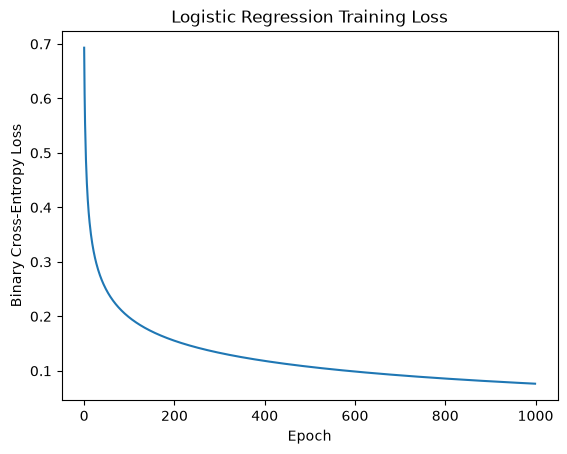

In [61]:
# plotting the loss curve
import matplotlib.pyplot as plt

plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression Training Loss")
plt.show()
